<a href="https://colab.research.google.com/github/JabbarHakim/Vision-Computer/blob/main/Deep_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q kagglehub tensorflow scikit-learn matplotlib seaborn

# Download the dataset

In [11]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download(
    "samuelcortinhas/cats-and-dogs-image-classification"
)

print("Path to dataset files:", path)

100%|██████████| 64.4M/64.4M [00:00<00:00, 190MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/samuelcortinhas/cats-and-dogs-image-classification/versions/4


# Inspect the dataset structure

In [12]:
import os

for root, dirs, files in os.walk(path):
    print(root, "->", len(files), "files")

    # Limit output depth
    if root.count(os.sep) - path.count(os.sep) >= 2:
        dirs[:] = []

/root/.cache/kagglehub/datasets/samuelcortinhas/cats-and-dogs-image-classification/versions/4 -> 0 files
/root/.cache/kagglehub/datasets/samuelcortinhas/cats-and-dogs-image-classification/versions/4/train -> 0 files
/root/.cache/kagglehub/datasets/samuelcortinhas/cats-and-dogs-image-classification/versions/4/train/dogs -> 278 files
/root/.cache/kagglehub/datasets/samuelcortinhas/cats-and-dogs-image-classification/versions/4/train/cats -> 279 files
/root/.cache/kagglehub/datasets/samuelcortinhas/cats-and-dogs-image-classification/versions/4/test -> 0 files
/root/.cache/kagglehub/datasets/samuelcortinhas/cats-and-dogs-image-classification/versions/4/test/dogs -> 70 files
/root/.cache/kagglehub/datasets/samuelcortinhas/cats-and-dogs-image-classification/versions/4/test/cats -> 70 files


# Load and split the dataset

In [13]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from collections import Counter

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

image_paths = []
labels = []

# Label mapping: Cats = 0, Dogs = 1
for file in Path(path).rglob("*"):
    if not file.is_file() or file.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    # Identify the class from the parent folder names
    folder_names = [part.lower() for part in file.parts[:-1]]

    if any(name in {"cats", "cat"} for name in folder_names):
        label = 0
    elif any(name in {"dogs", "dog"} for name in folder_names):
        label = 1
    else:
        continue

    image_paths.append(str(file))
    labels.append(label)

if len(image_paths) == 0:
    raise ValueError(
        "No images found in cats/dogs folders. "
        "Inspect the dataset structure from Step 2."
    )

print("Total images:", len(image_paths))
print("Class distribution:", Counter(labels))

# Split into training (70%) and temporary data (30%)
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Split temporary data equally into validation and testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

Total images: 697
Class distribution: Counter({0: 349, 1: 348})
Training images: 487
Validation images: 105
Testing images: 105


# Display sample images from the dataset

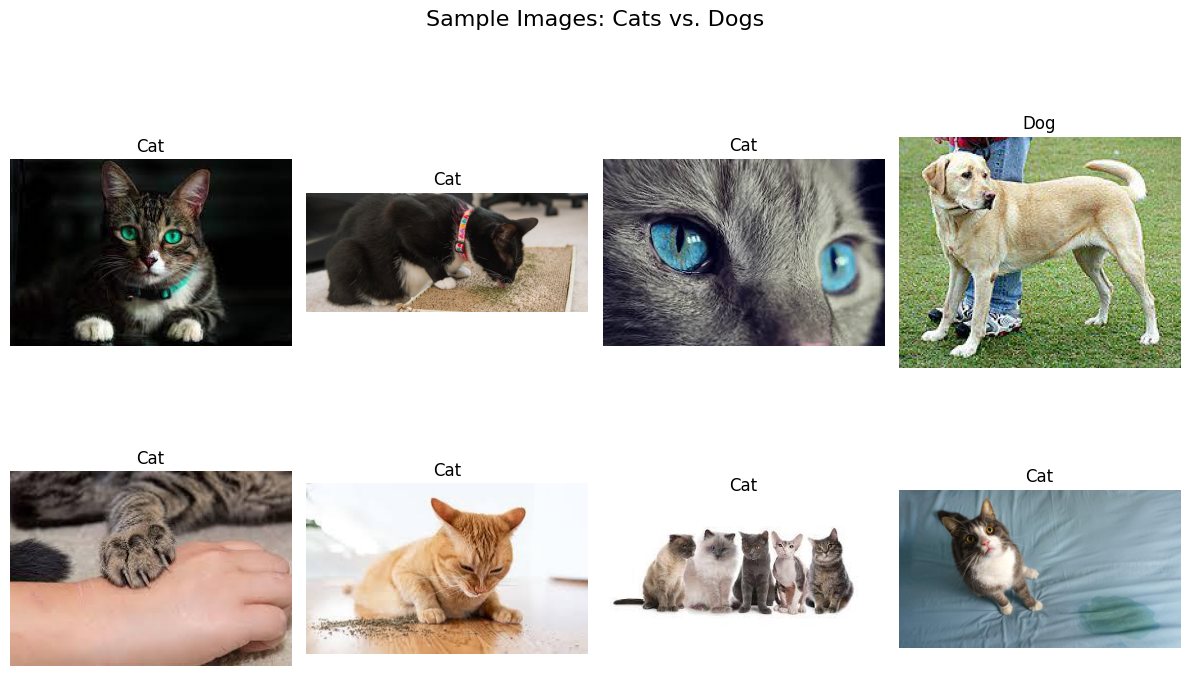

In [14]:
import matplotlib.pyplot as plt
from PIL import Image

plt.figure(figsize=(12, 8))

for i in range(min(8, len(X_train))):
    image = Image.open(X_train[i]).convert("RGB")

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title("Cat" if y_train[i] == 0 else "Dog")
    plt.axis("off")

plt.suptitle("Sample Images: Cats vs. Dogs", fontsize=16)
plt.tight_layout()
plt.show()

# Visualize the class distribution

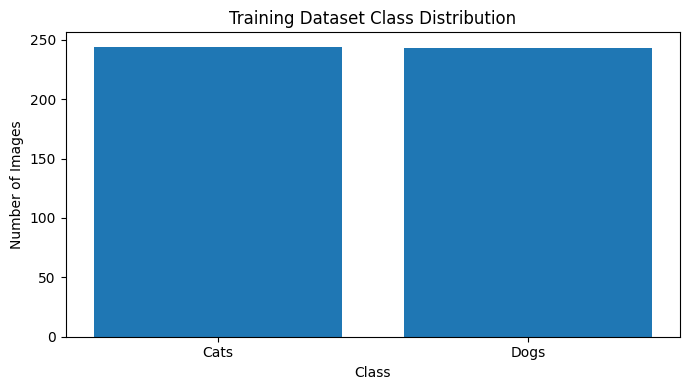

Cats: 244
Dogs: 243


In [15]:
import matplotlib.pyplot as plt
from collections import Counter

counts = Counter(y_train)

class_names = ["Cats", "Dogs"]
class_counts = [counts.get(0, 0), counts.get(1, 0)]

plt.figure(figsize=(7, 4))
plt.bar(class_names, class_counts)
plt.title("Training Dataset Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

print("Cats:", class_counts[0])
print("Dogs:", class_counts[1])

# Prepare the image data

In [16]:
import tensorflow as tf

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

def preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = image / 255.0

    return image, tf.cast(label, tf.float32)

def create_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=42
        )

    ds = ds.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = create_dataset(X_train, y_train, training=True)
val_ds = create_dataset(X_val, y_val)
test_ds = create_dataset(X_test, y_test)

# Build the CNN architecture

In [17]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 57600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     7,372,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,392,449 (28.20 MB)

 Trainable params: 7,392,449 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

# Train the model

In [18]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 21s 980ms/step - accuracy: 0.4908 - loss: 1.1428 - val_accuracy: 0.5048 - val_loss: 0.6935
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 16s 961ms/step - accuracy: 0.5688 - loss: 0.6774 - val_accuracy: 0.5143 - val_loss: 0.6746
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 15s 954ms/step - accuracy: 0.6057 - loss: 0.6467 - val_accuracy: 0.6476 - val_loss: 0.6474
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.6982 - loss: 0.5912 - val_accuracy: 0.6571 - val_loss: 0.6334
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.7803 - loss: 0.4781 - val_accuracy: 0.6190 - val_loss: 0.6601
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 27s 2s/step - accuracy: 0.8624 - loss: 0.3719 - val_accuracy: 0.6667 - val_loss: 0.6618
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.9158 - loss: 0.2486 - val_accuracy: 0.6571 - val_loss: 0.8397
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.9487 - loss: 0.1899 - val_accuracy: 0.6952 - 

# Plot training accuracy and loss

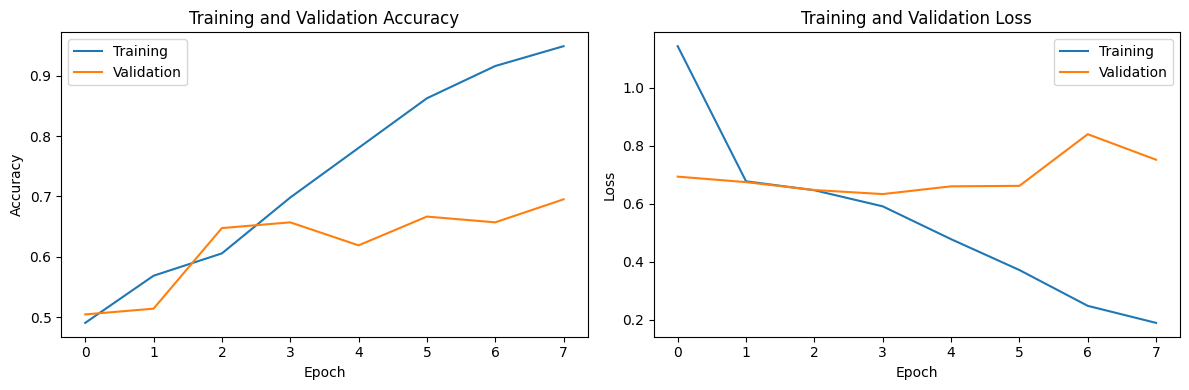

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# Evaluate the model

=== MODEL EVALUATION RESULTS ===
Accuracy  : 0.6286 (62.86%)
Precision : 0.6857 (68.57%)
Recall    : 0.4615 (46.15%)
F1-score  : 0.5517 (55.17%)

Classification Report:
              precision    recall  f1-score   support

        Cats       0.60      0.79      0.68        53
        Dogs       0.69      0.46      0.55        52

    accuracy                           0.63       105
   macro avg       0.64      0.63      0.62       105
weighted avg       0.64      0.63      0.62       105



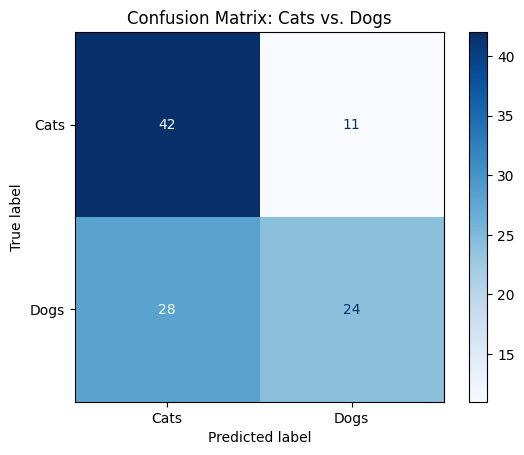

In [20]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Predict the test images
y_prob = model.predict(test_ds, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

# Actual test labels in the same order as the test dataset
y_true = np.asarray(y_test, dtype=int)

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, zero_division=0
)
recall = recall_score(
    y_true, y_pred, zero_division=0
)
f1 = f1_score(
    y_true, y_pred, zero_division=0
)

print("=== MODEL EVALUATION RESULTS ===")
print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall    : {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1-score  : {f1:.4f} ({f1 * 100:.2f}%)")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Cats", "Dogs"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Cats", "Dogs"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix: Cats vs. Dogs")
plt.show()

# Display sample predictions

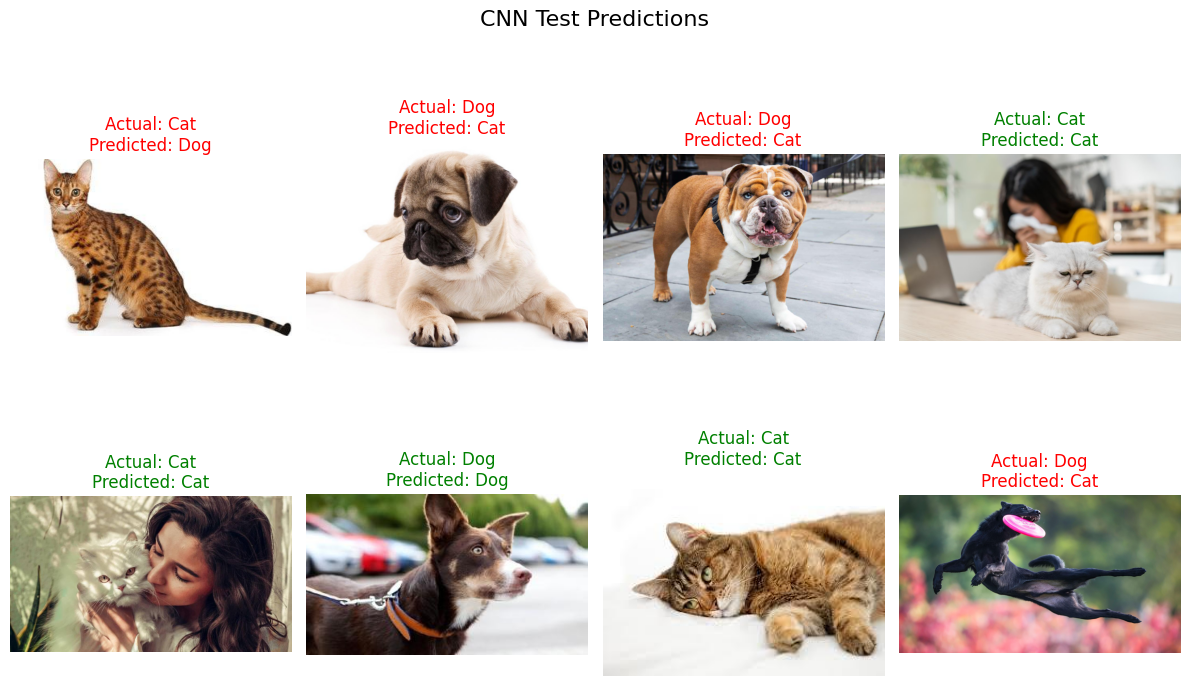

In [21]:
plt.figure(figsize=(12, 8))

for i in range(min(8, len(X_test))):
    image = Image.open(X_test[i]).convert("RGB")

    actual = "Dog" if y_true[i] == 1 else "Cat"
    predicted = "Dog" if y_pred[i] == 1 else "Cat"

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color="green" if actual == predicted else "red"
    )
    plt.axis("off")

plt.suptitle("CNN Test Predictions", fontsize=16)
plt.tight_layout()
plt.show()